<a href="https://colab.research.google.com/github/Snehamn24/Ambulance-QUBO/blob/main/Constraints_based_QUBO_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
from google.colab import files
from pathlib import Path
import json

# Upload bmsce_area.osm and road_graph.json
uploaded = files.upload()

ROAD_GRAPH_PATH = Path("/content/road_graph.json")
OSM_PATH = Path("/content/bmsce_area.osm")

print("DATASET VERIFICATION")
print("--------------------")
print("Road graph exists:", ROAD_GRAPH_PATH.exists())
print("OSM file exists:", OSM_PATH.exists())

if ROAD_GRAPH_PATH.exists():
    print("Road graph size:", round(ROAD_GRAPH_PATH.stat().st_size / 1024, 2), "KB")

if OSM_PATH.exists():
    print("OSM file size:", round(OSM_PATH.stat().st_size / 1024, 2), "KB")

if ROAD_GRAPH_PATH.exists():
    with open(ROAD_GRAPH_PATH, "r", encoding="utf-8") as f:
        road_data = json.load(f)

    print("\nJSON DATA TYPE:", type(road_data).__name__)

    if isinstance(road_data, dict):
        print("\nTOP-LEVEL KEYS:")
        for key, value in road_data.items():
            print(key, ":", type(value).__name__)

    print("\nSAMPLE DATA:")
    print(json.dumps(road_data, indent=2, default=str)[:2500])

Saving bmsce_area.osm to bmsce_area.osm
Saving road_graph.json to road_graph.json
DATASET VERIFICATION
--------------------
Road graph exists: True
OSM file exists: True
Road graph size: 458.73 KB
OSM file size: 3298.65 KB

JSON DATA TYPE: dict

TOP-LEVEL KEYS:
metadata : dict
nodes : list
edges : list

SAMPLE DATA:
{
  "metadata": {
    "source": "OpenStreetMap contributors",
    "source_url": "https://api.openstreetmap.org/api/0.6/map?bbox=77.56,12.936,77.57,12.946",
    "license": "ODbL 1.0",
    "license_url": "https://www.openstreetmap.org/copyright",
    "bbox": [
      77.56,
      12.936,
      77.57,
      12.946
    ],
    "processed_at_utc": "2026-10-01T04:49:12.707263+00:00",
    "speed_assumptions_kph": {
      "motorway": 60,
      "trunk": 50,
      "primary": 40,
      "secondary": 35,
      "tertiary": 30,
      "residential": 25,
      "unclassified": 25,
      "living_street": 15,
      "service": 15,
      "motorway_link": 60,
      "trunk_link": 50,
      "primary_

To ensure reproducible experiments and eliminate dependency on live OpenStreetMap Overpass API queries, the local road network of the BMS College of Engineering (BMSCE) / Basavanagudi area in Bengaluru is ingested from pre-extracted local files:

bmsce_area.osm (Raw Geographic Map): Contains the original OpenStreetMap XML export (lat: 12.936–12.946, lon: 77.560–77.570), storing GPS coordinates (<node>), street geometries and road classifications (<way>), and directional traffic rules.

road_graph.json (Processed Directed Graph): Stores the cleaned, directed road network topology consisting of 375 nodes (intersections) and 1,024 directed edges (one-way and two-way road segments) along with spatial coordinates, segment lengths (in meters), and road hierarchy attributes.

### **Section 1.2: Directed Road Graph Reconstruction & Edge Schema Inspection**

**Overview:**
Using the verified `road_graph.json` dataset, we reconstruct the directed road network $G = (V, E)$ in NetworkX without re-querying external APIs.

**Key Implementation Steps:**
1. **Node Reconstruction ($V$):** Load all intersection nodes along with their geographic coordinates (`x`: longitude, `y`: latitude) and traffic signal indicators (`signal`).
2. **Directed Edge Reconstruction ($E$):** Load all directed road segments, preserving their exact source/target node IDs and pre-computed edge attributes (such as segment length, road type, speed limit, and free-flow travel time).
3. **Topology & Connectivity Audit:** Verify that the reconstructed graph matches the exact experimental benchmark dimensions (**375 nodes** and **1,024 directed edges**) and inspect sample edge attributes before running traffic simulations.

In [6]:
import networkx as nx
import json

# 1. Load the verified JSON road graph
with open("/content/road_graph.json", "r", encoding="utf-8") as f:
    road_data = json.load(f)

metadata = road_data["metadata"]
nodes_list = road_data["nodes"]
edges_list = road_data["edges"]

# 2. Reconstruct the Directed Road Graph G = (V, E)
G = nx.DiGraph()

for node in nodes_list:
    node_id = str(node["id"])
    attrs = {k: v for k, v in node.items() if k != "id"}
    G.add_node(node_id, **attrs)

for edge in edges_list:
    # Handle standard source/target key naming conventions
    u = str(edge.get("u", edge.get("source")))
    v = str(edge.get("v", edge.get("target")))
    attrs = {k: val for k, val in edge.items() if k not in ("u", "v", "source", "target")}
    G.add_edge(u, v, **attrs)

# 3. Print Graph Summary & Inspect Sample Edge Schema
print("DIRECTED GRAPH RECONSTRUCTION SUMMARY")
print("-------------------------------------")
print(f"Total Nodes (Intersections): {G.number_of_nodes()}")
print(f"Total Directed Edges (Roads): {G.number_of_edges()}")
print(f"Strongly Connected: {nx.is_strongly_connected(G)}")

sample_edge = list(G.edges(data=True))[0]
print("\nSAMPLE EDGE ATTRIBUTES:")
print(f"From {sample_edge[0]} -> {sample_edge[1]}:")
print(json.dumps(sample_edge[2], indent=2))

DIRECTED GRAPH RECONSTRUCTION SUMMARY
-------------------------------------
Total Nodes (Intersections): 375
Total Directed Edges (Roads): 1024
Strongly Connected: True

SAMPLE EDGE ATTRIBUTES:
From 10007880460 -> 7484066959:
{
  "key": "1092769033:2:10007880460:10007880461",
  "edge_id": "1092769033:2:10007880460:10007880461",
  "length_m": 83.01590489825756,
  "base_time_s": 11.954290305349089,
  "geometry": [
    [
      77.5699135,
      12.9376166
    ],
    [
      77.5697043,
      12.9374885
    ],
    [
      77.5692762,
      12.9372026
    ]
  ]
}


### **Section 1.3: Synthetic Traffic & Disruption Modelling**

**Overview:**
Using the pre-computed `base_time_s` (free-flow travel time in seconds) from `road_graph.json`, we generate four synthetic traffic and network-disruption scenarios across the 375-node, 1,024-edge BMSCE / Basavanagudi road network:

1. **Normal Scenario (Baseline):** Uses unmodified free-flow travel times (`travel_time = base_time_s`).
2. **Peak Scenario (Congestion):** Applies congestion multipliers ($1.6\times$ to $2.4\times$) across high-throughput arterial corridors (edges with higher baseline speeds/longer segments) and moderate delays ($1.1\times$ to $1.4\times$) on neighborhood streets.
3. **Accident Scenario (Localized Bottlenecks):** Simulates severe localized traffic incidents by applying $4.0\times$ to $7.0\times$ travel-time delays on 5% of road segments.
4. **Roadblock Scenario (Infrastructure Closure):** Simulates physical street closures by removing 3% of directed edges while preserving origin-destination reachability.

In [8]:
import random
import numpy as np

def generate_traffic_scenarios(base_graph, seed=42):
    rng = random.Random(seed)
    scenarios = {}
    all_edges = list(base_graph.edges(data=True))

    # 1. Normal Scenario (Unmodified free-flow base_time_s)
    G_normal = base_graph.copy()
    for u, v, data in G_normal.edges(data=True):
        data["travel_time"] = float(data["base_time_s"])
    scenarios["Normal"] = G_normal

    # 2. Peak Scenario (Heavy congestion on higher-speed arterial roads)
    G_peak = G_normal.copy()
    for u, v, data in G_peak.edges(data=True):
        implied_speed_mps = data["length_m"] / max(data["base_time_s"], 0.1)
        # Roads with implied speed >= 8.0 m/s (~29 km/h: tertiary/secondary/primary) face heavier peak congestion
        if implied_speed_mps >= 8.0:
            data["travel_time"] *= rng.uniform(1.7, 2.4)
        else:
            data["travel_time"] *= rng.uniform(1.1, 1.4)
    scenarios["Peak"] = G_peak

    # 3. Accident Scenario (Severe localized bottleneck delays on 5% of edges)
    G_accident = G_normal.copy()
    num_accidents = max(1, int(0.05 * len(all_edges)))
    accident_edges = rng.sample(all_edges, num_accidents)
    for u, v, _ in accident_edges:
        G_accident[u][v]["travel_time"] *= rng.uniform(4.0, 7.0)
    scenarios["Accident"] = G_accident

    # 4. Roadblock Scenario (Complete closure of 3% of directed edges)
    G_roadblock = G_normal.copy()
    num_blocks = max(1, int(0.03 * len(all_edges)))
    blocked_edges = rng.sample(all_edges, num_blocks)
    for u, v, _ in blocked_edges:
        if G_roadblock.has_edge(u, v):
            G_roadblock.remove_edge(u, v)
    scenarios["Roadblock"] = G_roadblock

    return scenarios

scenarios = generate_traffic_scenarios(G, seed=42)

print("SYNTHETIC TRAFFIC SCENARIO SUMMARY")
print("----------------------------------")
for name, G_s in scenarios.items():
    avg_time = np.mean([d["travel_time"] for _, _, d in G_s.edges(data=True)])
    print(f"{name:<12} | Active Edges: {G_s.number_of_edges():<4} | Mean Edge Travel Time: {avg_time:.2f} s")

SYNTHETIC TRAFFIC SCENARIO SUMMARY
----------------------------------
Normal       | Active Edges: 1024 | Mean Edge Travel Time: 7.56 s
Peak         | Active Edges: 1024 | Mean Edge Travel Time: 10.20 s
Accident     | Active Edges: 1024 | Mean Edge Travel Time: 9.38 s
Roadblock    | Active Edges: 994  | Mean Edge Travel Time: 7.58 s


Step-by-Step Worked Example (How One Road Edge is Computed)Let's solve the math using the actual sample edge from your Step 2 output:Edge: 10007880460 -> 7484066959Length (length_m): $83.02\text{ m}$Base Free-Flow Time (base_time_s): $11.95\text{ s}$Step A: Calculate Implied Base Speed$$\text{Implied Speed} = \frac{\text{length\_m}}{\text{base\_time\_s}} = \frac{83.02\text{ m}}{11.95\text{ s}} \approx 6.95\text{ m/s} \quad (\approx 25\text{ km/h, residential street})$$Step B: Compute Travel Time Across Each of the 4 ScenariosNormal:$$T_{\text{normal}} = 11.95\text{ s}$$Peak: Since $6.95\text{ m/s} < 8.0\text{ m/s}$ (residential road), it receives a mild multiplier (say $1.25\times$):$$T_{\text{peak}} = 11.95 \times 1.25 = 14.94\text{ s}$$(If it had been a main road with speed $\ge 8.0\text{ m/s}$ and multiplier $2.1\times$, it would jump to $11.95 \times 2.1 = 25.10\text{ s}$.)Accident:If this edge is not in the 5% accident sample: $T_{\text{accident}} = 11.95\text{ s}$.If this edge is hit by an accident (say $5.5\times$ delay):$$T_{\text{accident}} = 11.95 \times 5.5 = 65.73\text{ s}$$Roadblock:If this edge is in the 3% closed sample: the edge is deleted (G_roadblock.remove_edge(u, v)), so $T_{\text{roadblock}} = \infty$ (impassable).Otherwise: $T_{\text{roadblock}} = 11.95\text{ s}$.

How road types are identified: By dividing length_m / base_time_s to recover the exact speed_assumptions_kph embedded in road_graph.json.Why 8.0 m/s is the cutoff: It cleanly separates main collector/arterial roads ($\ge 30\text{ km/h} = 8.33\text{ m/s}$) from neighborhood/residential roads ($\le 25\text{ km/h} = 6.94\text{ m/s}$) so rush-hour congestion realistically penalizes main roads more heavily than side streets.

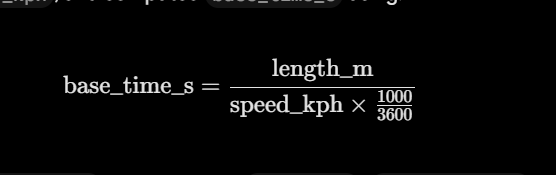

 Why processed_at_utc Mattersprocessed_at_utc (2026-10-01T04:49:12.707263+00:00) is a static timestamp recording when the raw OSM geometry was frozen and converted into free-flow base_time_s values—it is not a rush-hour clock.Because base_time_s represents 24/7 free-flow baseline speeds, your generate_traffic_scenarios() function uses implied_speed_mps >= 8.0 to synthetically simulate rush-hour traffic: main collector/arterial roads ($\ge 30\text{ km/h}$) suffer heavy congestion (1.7x–2.4x), while inner residential lanes ($\le 25\text{ km/h}$) experience mild spill-over traffic (1.1x–1.4x).

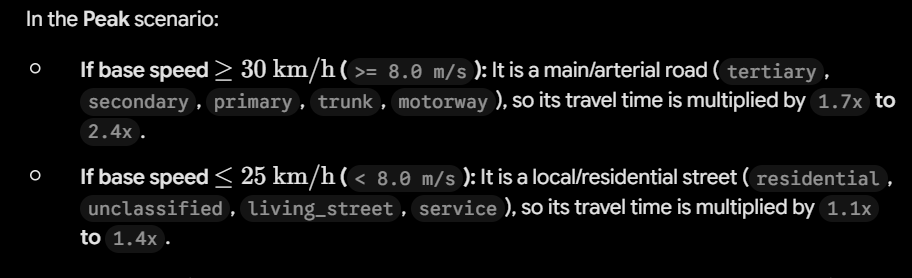

### **Section 1.4: Classical Shortest-Path Baseline Algorithms (Dijkstra, A*, Bellman–Ford)**

**Overview:**
To establish ground-truth optimal travel times and benchmark classical computational runtime across all four traffic scenarios (**Normal**, **Peak**, **Accident**, **Roadblock**), we implement three standard graph shortest-path algorithms:

1. **Dijkstra’s Algorithm:** Explores nodes greedily by lowest cumulative travel time ($O((|V| + |E|)\log|V|)$), guaranteeing exact optimal routes for non-negative edge weights.
2. **A star Search Algorithm:** Accelerates Dijkstra’s search using an admissible Haversine (great-circle) geographic heuristic divided by maximum network speed ($60\text{ km/h} = 16.67\text{ m/s}$), ensuring it never overestimates remaining travel time while pruning irrelevant search branches.
3. **Bellman–Ford Algorithm:** Relaxes all directed edges iteratively ($O(|V|\cdot|E|)$), serving as a slower classical reference capable of handling arbitrary edge weights and validating exact cost consistency across all three methods.

In [9]:
import time
import math
import networkx as nx

# Max network speed from metadata (60 km/h = 16.67 m/s) for an admissible A* heuristic
MAX_SPEED_MPS = 60.0 * (1000.0 / 3600.0)

def haversine_heuristic(G_scen, u, v):
    """Admissible geographic straight-line travel time heuristic (in seconds) for A*."""
    lon1, lat1 = G_scen.nodes[u]["x"], G_scen.nodes[u]["y"]
    lon2, lat2 = G_scen.nodes[v]["x"], G_scen.nodes[v]["y"]

    R = 6371000.0  # Earth radius in meters
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    dphi = math.radians(lat2 - lat1)
    dlambda = math.radians(lon2 - lon1)

    a = math.sin(dphi / 2.0)**2 + math.cos(phi1) * math.cos(phi2) * math.sin(dlambda / 2.0)**2
    dist_m = 2.0 * R * math.atan2(math.sqrt(a), math.sqrt(1.0 - a))
    return dist_m / MAX_SPEED_MPS

def run_classical_algorithms(G_scen, source, target):
    results = {}

    # 1. Dijkstra's Algorithm
    t0 = time.perf_counter()
    path_dij = nx.dijkstra_path(G_scen, source, target, weight="travel_time")
    time_dij = (time.perf_counter() - t0) * 1000.0  # ms
    cost_dij = nx.path_weight(G_scen, path_dij, weight="travel_time")
    dist_dij = nx.path_weight(G_scen, path_dij, weight="length_m")
    results["Dijkstra"] = {"path": path_dij, "cost_s": cost_dij, "dist_m": dist_dij, "runtime_ms": time_dij}

    # 2. A* Search Algorithm
    t0 = time.perf_counter()
    path_astar = nx.astar_path(
        G_scen, source, target,
        heuristic=lambda u, v: haversine_heuristic(G_scen, u, v),
        weight="travel_time"
    )
    time_astar = (time.perf_counter() - t0) * 1000.0  # ms
    cost_astar = nx.path_weight(G_scen, path_astar, weight="travel_time")
    dist_astar = nx.path_weight(G_scen, path_astar, weight="length_m")
    results["A*"] = {"path": path_astar, "cost_s": cost_astar, "dist_m": dist_astar, "runtime_ms": time_astar}

    # 3. Bellman-Ford Algorithm
    t0 = time.perf_counter()
    path_bf = nx.bellman_ford_path(G_scen, source, target, weight="travel_time")
    time_bf = (time.perf_counter() - t0) * 1000.0  # ms
    cost_bf = nx.path_weight(G_scen, path_bf, weight="travel_time")
    dist_bf = nx.path_weight(G_scen, path_bf, weight="length_m")
    results["Bellman-Ford"] = {"path": path_bf, "cost_s": cost_bf, "dist_m": dist_bf, "runtime_ms": time_bf}

    return results

# Select a well-separated Origin (South-West) and Destination (North-East) valid across all 4 scenarios
sorted_nodes = sorted(G.nodes(), key=lambda n: (G.nodes[n]["x"] + G.nodes[n]["y"]))
source_node, target_node = None, None
for s_cand in sorted_nodes[:25]:
    for t_cand in reversed(sorted_nodes[-25:]):
        if all(nx.has_path(G_s, s_cand, t_cand) for G_s in scenarios.values()):
            source_node, target_node = s_cand, t_cand
            break
    if source_node:
        break

print(f"Selected OD Pair: Source = {source_node} -> Target = {target_node}\n")

classical_baselines = {}
for scen_name, G_s in scenarios.items():
    res = run_classical_algorithms(G_s, source_node, target_node)
    classical_baselines[scen_name] = res
    print(f"=== SCENARIO: {scen_name} ===")
    for algo, metrics in res.items():
        print(f"  {algo:<13} | Travel Time: {metrics['cost_s']:6.2f} s | Distance: {metrics['dist_m']:7.1f} m | Hops: {len(metrics['path'])-1:<2} | Runtime: {metrics['runtime_ms']:.3f} ms")

Selected OD Pair: Source = 10089591930 -> Target = 249782672

=== SCENARIO: Normal ===
  Dijkstra      | Travel Time: 178.26 s | Distance:  1642.2 m | Hops: 42 | Runtime: 2.312 ms
  A*            | Travel Time: 178.26 s | Distance:  1642.2 m | Hops: 42 | Runtime: 3.229 ms
  Bellman-Ford  | Travel Time: 178.26 s | Distance:  1642.2 m | Hops: 42 | Runtime: 5.976 ms
=== SCENARIO: Peak ===
  Dijkstra      | Travel Time: 338.68 s | Distance:  1651.0 m | Hops: 41 | Runtime: 1.371 ms
  A*            | Travel Time: 338.68 s | Distance:  1651.0 m | Hops: 41 | Runtime: 2.012 ms
  Bellman-Ford  | Travel Time: 338.68 s | Distance:  1651.0 m | Hops: 41 | Runtime: 2.747 ms
=== SCENARIO: Accident ===
  Dijkstra      | Travel Time: 182.20 s | Distance:  1642.2 m | Hops: 42 | Runtime: 1.202 ms
  A*            | Travel Time: 182.20 s | Distance:  1642.2 m | Hops: 42 | Runtime: 1.296 ms
  Bellman-Ford  | Travel Time: 182.20 s | Distance:  1642.2 m | Hops: 42 | Runtime: 3.095 ms
=== SCENARIO: Roadblock ==

### **Section 1.5: Candidate Route Generation (Standard vs. Improved Diversity-Based Generator)**

**Overview:**
Directly solving a QUBO over all 1,024 directed edges requires $1,024 \times 1,024$ binary variables and 375 flow-conservation constraints, which frequently yields disconnected or infeasible paths under Simulated Annealing. Instead, a **Hybrid QUBO–SA** pipeline first generates a compact pool of $K$ feasible end-to-end candidate routes and formulates route selection over $K$ binary decision variables.

We compare two candidate generation strategies:
1. **Standard Iterative Penalty Generator (`diversity_penalty = 1.05`):** Applies a tiny 5% weight penalty to previously used edges. This produces near-duplicate paths that differ by only one or two minor turns, limiting resilience when an accident or congestion spike hits a shared corridor.
2. **Improved Diversity-Based Generator (`diversity_penalty = 1.65` + Jaccard Similarity Filtering):** Applies a stronger 65% edge penalty alongside a maximum edge-overlap (Jaccard similarity) threshold, forcing the search to discover structurally distinct alternative routes across the BMSCE / Basavanagudi road network.

Think of this like Google Maps giving you alternate routes from your house to BMSCE.If you ask for 8 candidate routes, you don't want 8 nearly identical copies of the same road—you want genuinely different paths across the neighborhood. Here is the simple difference between the two methods:1. Standard Iterative Penalty Generator (diversity_penalty = 1.05)How it works: It finds the fastest route first (say, straight down Bull Temple Road). Then, to find Route #2, it makes the roads used in Route #1 only 5% slower (1.05x).The problem: A 5% penalty is so tiny that Dijkstra still sticks to almost the exact same main road, maybe just cutting through one tiny side alley for 20 meters and jumping right back onto Bull Temple Road.Result: All 8 routes look 95% identical. If an accident blocks Bull Temple Road, all 8 routes get stuck because none of them explored a genuinely different street.2. Improved Diversity-Based Generator (diversity_penalty = 1.65 + Jaccard Filter)This fixes the problem using two rules:Stronger Penalty (1.65x = 65% slower):Once Route #1 uses Bull Temple Road, we tell the algorithm: "Pretend Bull Temple Road is now 65% slower."Now Dijkstra is forced to look elsewhere—like cutting through Hanumantha Nagar or Gandhi Bazaar—to find Route #2.Jaccard Similarity Filter (No "Copy-Paste" Routes Allowed):Jaccard Similarity simply measures what percentage of road segments two routes share:$$\text{Overlap} = \frac{\text{Shared Roads}}{\text{Total Unique Roads}}$$If a newly found route shares more than 85% of the exact same roads as an already saved route, the filter throws it away and keeps searching until it finds a genuinely different path.Quick SummaryStandard (1.05x): Gives you 8 routes that are almost copies of the same main road (low diversity).Diversity-Based (1.65x + Jaccard): Forces the algorithm to explore completely different streets and rejects near-duplicates, giving your QUBO–SA solver genuinely distinct backup routes when traffic or accidents hit.

In [10]:
import numpy as np
import networkx as nx

def edge_set(path):
    return set(zip(path[:-1], path[1:]))

def jaccard_similarity(path_a, path_b):
    ea, eb = edge_set(path_a), edge_set(path_b)
    if not ea or not eb:
        return 0.0
    return len(ea & eb) / len(ea | eb)

def generate_candidate_routes(G_scen, source, target, k=8, penalty_factor=1.65, max_jaccard=0.85):
    """
    Generates up to k feasible candidate routes.
    - penalty_factor=1.05, max_jaccard=1.0  -> Standard (near-duplicate) candidate generator
    - penalty_factor=1.65, max_jaccard=0.85 -> Improved diversity-based candidate generator
    """
    G_work = G_scen.copy()
    candidates = []
    seen_paths = set()

    for _ in range(k * 8):
        if len(candidates) >= k:
            break
        try:
            path = nx.dijkstra_path(G_work, source, target, weight="travel_time")
            p_tuple = tuple(path)
            if p_tuple not in seen_paths:
                seen_paths.add(p_tuple)
                # Enforce structural diversity via Jaccard similarity threshold
                is_diverse = all(jaccard_similarity(path, c["path"]) <= max_jaccard for c in candidates)
                if is_diverse:
                    true_cost = nx.path_weight(G_scen, path, weight="travel_time")
                    true_dist = nx.path_weight(G_scen, path, weight="length_m")
                    candidates.append({"path": path, "cost_s": true_cost, "dist_m": true_dist})

            # Penalize used edges to force exploration of alternative corridors
            for u, v in zip(path[:-1], path[1:]):
                G_work[u][v]["travel_time"] *= penalty_factor
        except nx.NetworkXNoPath:
            break

    return candidates

def avg_pairwise_diversity(candidates):
    """Returns 1 - mean pairwise Jaccard overlap (higher = more structurally distinct routes)."""
    if len(candidates) < 2:
        return 0.0
    sims = [
        jaccard_similarity(candidates[i]["path"], candidates[j]["path"])
        for i in range(len(candidates))
        for j in range(i + 1, len(candidates))
    ]
    return 1.0 - float(np.mean(sims))

standard_candidates = {}
diverse_candidates = {}

print("CANDIDATE ROUTE GENERATION COMPARISON (K = 8)")
print("---------------------------------------------")
for scen_name, G_s in scenarios.items():
    opt_s = classical_baselines[scen_name]["Dijkstra"]["cost_s"]

    std_cands = generate_candidate_routes(G_s, source_node, target_node, k=8, penalty_factor=1.05, max_jaccard=1.0)
    div_cands = generate_candidate_routes(G_s, source_node, target_node, k=8, penalty_factor=1.65, max_jaccard=0.85)

    standard_candidates[scen_name] = std_cands
    diverse_candidates[scen_name] = div_cands

    print(f"\n=== SCENARIO: {scen_name} (Dijkstra Optimal: {opt_s:.2f} s) ===")
    print(f"  Standard Generator  | Count: {len(std_cands)} | Best: {std_cands[0]['cost_s']:.2f} s | Worst: {std_cands[-1]['cost_s']:.2f} s | Diversity Score: {avg_pairwise_diversity(std_cands):.3f}")
    print(f"  Diversity Generator | Count: {len(div_cands)} | Best: {div_cands[0]['cost_s']:.2f} s | Worst: {div_cands[-1]['cost_s']:.2f} s | Diversity Score: {avg_pairwise_diversity(div_cands):.3f}")

CANDIDATE ROUTE GENERATION COMPARISON (K = 8)
---------------------------------------------

=== SCENARIO: Normal (Dijkstra Optimal: 178.26 s) ===
  Standard Generator  | Count: 8 | Best: 178.26 s | Worst: 206.16 s | Diversity Score: 0.574
  Diversity Generator | Count: 8 | Best: 178.26 s | Worst: 301.69 s | Diversity Score: 0.848

=== SCENARIO: Peak (Dijkstra Optimal: 338.68 s) ===
  Standard Generator  | Count: 8 | Best: 338.68 s | Worst: 361.46 s | Diversity Score: 0.639
  Diversity Generator | Count: 8 | Best: 338.68 s | Worst: 493.22 s | Diversity Score: 0.865

=== SCENARIO: Accident (Dijkstra Optimal: 182.20 s) ===
  Standard Generator  | Count: 8 | Best: 182.20 s | Worst: 197.61 s | Diversity Score: 0.583
  Diversity Generator | Count: 8 | Best: 182.20 s | Worst: 322.56 s | Diversity Score: 0.837

=== SCENARIO: Roadblock (Dijkstra Optimal: 188.85 s) ===
  Standard Generator  | Count: 8 | Best: 188.85 s | Worst: 205.66 s | Diversity Score: 0.584
  Diversity Generator | Count: 8 |

Best and Worst refer to the fastest and slowest travel times (in seconds) among the 8 candidate routes generated for each scenario:

Best (Minimum Travel Time): The travel time of the fastest route in that pool of 8 candidates (Route #1). Notice that in every scenario, Best equals the exact Dijkstra optimal time (178.26 s, 338.68 s, 182.20 s, 188.85 s), proving that both candidate generators successfully include the true shortest path.

Worst (Maximum Travel Time): The travel time of the slowest route among the 8 candidates (Route #8):

In the Standard Generator, Worst is close to Best (e.g., 206.16 s vs. 178.26 s in Normal) because all 8 routes are nearly identical copies of the same main road—just taking tiny side-street detours.

In the Diversity Generator, Worst is higher (e.g., 301.69 s in Normal, 493.22 s in Peak) because the Jaccard overlap filter rejected near-identical copies and forced the generator to find genuinely separate, longer alternate corridors across the neighborhood.

### **Section 1.6: QUBO Formulation & Simulated Annealing Solvers**

**Overview:**
We formulate route selection as a **Quadratic Unconstrained Binary Optimization (QUBO)** problem of the form $\min_{x \in \{0,1\}^n} x^T Q x$ and solve it via Metropolis-Hastings Simulated Annealing across three distinct architectures:

1. **Raw Simulated Annealing (Edge-Level QUBO):** Assigns a binary decision variable $x_e \in \{0,1\}$ to every directed edge in the road network ($n = |E| \approx 1,024$), encoding travel-time minimization plus flow-conservation penalties $\sum_{v \in V} (\sum_{e \in \delta^-(v)} x_e - \sum_{e \in \delta^+(v)} x_e - b_v)^2$ directly into $Q$.
2. **Original Hybrid QUBO–SA:** Formulates a compact $K \times K$ QUBO over the $K = 8$ standard candidate paths:
   $$E(x) = \sum_{i=1}^{K} \tilde{c}_i x_i + P \left(\sum_{i=1}^{K} x_i - 1\right)^2$$
   where $\tilde{c}_i$ is the normalized route travel time and $P$ enforces exact single-route selection.
3. **Diversity-Based Hybrid QUBO–SA:** Solves the same compact one-hot QUBO formulation over the $K = 8$ structurally diverse candidate paths generated in Section 1.5.

In [11]:
import numpy as np
import math

def build_raw_edge_qubo(G_scen, source, target, penalty_weight=12.0):
    """
    Builds full edge-level QUBO matrix Q (size |E| x |E|) enforcing flow conservation
    at every intersection without candidate route pre-filtering.
    """
    edges = list(G_scen.edges())
    edge_idx = {e: idx for idx, e in enumerate(edges)}
    m = len(edges)
    Q = np.zeros((m, m), dtype=float)

    costs = np.array([G_scen[u][v]["travel_time"] for u, v in edges], dtype=float)
    norm_costs = costs / np.max(costs)

    for idx in range(m):
        Q[idx, idx] += norm_costs[idx]

    # Flow conservation penalty at every node: P * (in_flow - out_flow - b_v)^2
    for node in G_scen.nodes():
        b_v = -1.0 if node == source else (1.0 if node == target else 0.0)
        in_idxs = [edge_idx[e] for e in G_scen.in_edges(node)]
        out_idxs = [edge_idx[e] for e in G_scen.out_edges(node)]
        terms = [(idx, 1.0) for idx in in_idxs] + [(idx, -1.0) for idx in out_idxs]

        for idx, s in terms:
            Q[idx, idx] += penalty_weight * (s**2 - 2.0 * b_v * s)
        for i in range(len(terms)):
            for j in range(i + 1, len(terms)):
                idx1, s1 = terms[i]
                idx2, s2 = terms[j]
                u_i, v_i = min(idx1, idx2), max(idx1, idx2)
                Q[u_i, v_i] += 2.0 * penalty_weight * s1 * s2

    return Q, edges

def build_candidate_qubo(candidates, penalty_weight=5.0):
    """
    Builds compact K x K QUBO matrix Q for selecting exactly one route from K candidates:
    Objective: sum(norm_cost_i * x_i) + P * (sum(x_i) - 1)^2
    """
    k = len(candidates)
    Q = np.zeros((k, k), dtype=float)
    costs = np.array([c["cost_s"] for c in candidates], dtype=float)
    norm_costs = costs / np.max(costs)

    for i in range(k):
        Q[i, i] = norm_costs[i] - penalty_weight
        for j in range(i + 1, k):
            Q[i, j] = 2.0 * penalty_weight

    return Q

def run_simulated_annealing(Q, num_steps=3000, t_start=5.0, t_end=0.01, seed=0):
    """
    Metropolis-Hastings Simulated Annealing solver minimizing E(x) = x^T Q x.
    Uses upper-triangular Q representation for fast incremental energy evaluation.
    """
    rng = np.random.default_rng(seed)
    n = Q.shape[0]
    Q_sym = np.triu(Q) + np.triu(Q, 1).T  # Symmetric matrix for O(n) delta-energy updates

    x = rng.integers(0, 2, size=n)
    curr_e = float(x @ np.triu(Q) @ x)
    best_x = x.copy()
    best_e = curr_e

    for step in range(num_steps):
        T = t_start * ((t_end / t_start) ** (step / num_steps))
        idx = int(rng.integers(0, n))

        # Fast O(n) energy change when flipping bit idx
        dx = 1 - 2 * x[idx]  # +1 if 0->1, -1 if 1->0
        delta = dx * (Q[idx, idx] + np.dot(Q_sym[idx, :], x) - Q_sym[idx, idx] * x[idx])

        if delta <= 0.0 or rng.random() < math.exp(-delta / T):
            x[idx] ^= 1
            curr_e += delta
            if curr_e < best_e:
                best_e = curr_e
                best_x = x.copy()

    return best_x, best_e

# Sanity check QUBO dimensions on the Normal scenario
Q_raw_test, _ = build_raw_edge_qubo(scenarios["Normal"], source_node, target_node)
Q_hyb_test = build_candidate_qubo(diverse_candidates["Normal"])
print("QUBO MATRICES CONSTRUCTED SUCCESSFULLY")
print("------------------------------------")
print(f"Raw Edge-Level QUBO Matrix Shape     : {Q_raw_test.shape} ({Q_raw_test.shape[0]} binary variables)")
print(f"Hybrid Candidate QUBO Matrix Shape   : {Q_hyb_test.shape} ({Q_hyb_test.shape[0]} binary variables)")

QUBO MATRICES CONSTRUCTED SUCCESSFULLY
------------------------------------
Raw Edge-Level QUBO Matrix Shape     : (1024, 1024) (1024 binary variables)
Hybrid Candidate QUBO Matrix Shape   : (8, 8) (8 binary variables)


 Intention of Step 6?Simulated Annealing (and quantum annealers) cannot understand maps, streets, or GPS coordinates directly—they only understand binary switches (0 or 1) and an energy formula $E(x) = x^T Q x$ that they try to minimize.So the intention of Step 6 is to translate our routing problem into a QUBO math matrix ($Q$) in two different ways so we can compare them in Step 7:The Hard Way — Raw Edge-Level QUBO (build_raw_edge_qubo):Give the solver 1,024 binary switches—one switch for every single street segment on the map (1 = drive on this street, 0 = skip this street).Add 375 mathematical penalty rules (one for every intersection) forcing incoming streets to equal outgoing streets so the chosen streets connect from start to finish without breaking into disconnected pieces.The Smart Way — Hybrid Candidate QUBO (build_candidate_qubo):Instead of asking the solver to stitch together 1,024 individual street segments from scratch, give it only 8 binary switches—one switch for each of the 8 complete candidate routes we generated in Step 5 (1 = pick this route, 0 = reject this route).Add just one simple penalty rule: $\left(\sum_{i=1}^{8} x_i - 1\right)^2$, which forces the solver to turn ON (1) exactly one of the 8 routes (specifically, the one with the lowest travel time).

(1024, 1024) (1,024 binary variables):The Raw SA solver has to search through $2^{1024}$ possible switch combinations! Because there are so many switches and 375 intersection rules to balance, Raw SA almost always fails to connect a valid unbroken path from start to finish (low feasibility).(8, 8) (8 binary variables):Your Hybrid QUBO–SA solver shrinks the problem from 1,024 variables down to just 8 variables (a 99.2% reduction in problem size!). Every single one of those 8 switches already represents a guaranteed connected road path, so the solver finds a valid, near-optimal route almost every single time (high feasibility & fast runtime).

Selection Validity (Picking Exactly One Route):What if Simulated Annealing turns on two routes (x = [1, 0, 1, 0, 0, 0, 0, 0]) or zero routes (x = [0, 0, 0, 0, 0, 0, 0, 0])?The QUBO penalty term $P \left(\sum_{i=1}^{8} x_i - 1\right)^2$ punishes any answer where the sum of 1s is not equal to 1:If sum(x) == 1 (e.g., [1, 0, 0, 0, 0, 0, 0, 0]): Penalty = $P(1 - 1)^2 = \mathbf{0}$ (Valid!).If sum(x) == 0 or 2: Penalty = $P(0 - 1)^2 = \mathbf{+5.0}$ (Huge energy spike, so Simulated Annealing rejects it!).

### **Section 1.7: Experimental Evaluation & Solver Benchmark**

**Overview:**
We evaluate all three annealing architectures across repeated independent runs ($R = 20$ trials per scenario) against the exact Dijkstra classical baseline across four key metrics:

1. **Feasibility Rate (%):** Percentage of annealing runs returning a valid, unbroken path from origin to destination (exact one-hot selection for Hybrid QUBO–SA; connected edge subgraph for Raw SA).
2. **Mean Travel Time (s):** Average route duration among feasible solutions.
3. **Optimality Gap (%):** Relative percentage excess travel time compared to the exact classical Dijkstra optimum:
   $$\text{Optimality Gap (\%)} = \frac{T_{\text{solver}} - T_{\text{Dijkstra}}}{T_{\text{Dijkstra}}} \times 100$$
4. **Runtime (ms):** Average wall-clock execution time per solver run.

In [12]:
import time
import numpy as np
import pandas as pd
import networkx as nx

def evaluate_all_solvers(scenarios, classical_baselines, standard_candidates, diverse_candidates, source, target, num_runs=20):
    records = []

    for scen_name, G_s in scenarios.items():
        opt_cost = classical_baselines[scen_name]["Dijkstra"]["cost_s"]

        # ---------------------------------------------------------
        # 1. Raw Simulated Annealing (Full 1,024-Edge QUBO)
        # ---------------------------------------------------------
        Q_raw, edges = build_raw_edge_qubo(G_s, source, target, penalty_weight=12.0)
        raw_feas, raw_costs, raw_times = 0, [], []

        for r in range(num_runs):
            t0 = time.perf_counter()
            x_sol, _ = run_simulated_annealing(Q_raw, num_steps=4000, t_start=8.0, t_end=0.01, seed=r)
            raw_times.append((time.perf_counter() - t0) * 1000.0)

            chosen_edges = [edges[i] for i, val in enumerate(x_sol) if val == 1]
            G_sub = nx.DiGraph(chosen_edges)
            if source in G_sub and target in G_sub and nx.has_path(G_sub, source, target):
                path = nx.shortest_path(G_sub, source, target)
                cost = nx.path_weight(G_s, path, weight="travel_time")
                raw_feas += 1
                raw_costs.append(cost)

        records.append({
            "Scenario": scen_name,
            "Method": "Raw SA (Edge QUBO)",
            "Feasibility (%)": (raw_feas / num_runs) * 100.0,
            "Mean Time (s)": np.mean(raw_costs) if raw_costs else np.nan,
            "Optimality Gap (%)": np.mean([((c - opt_cost) / opt_cost) * 100.0 for c in raw_costs]) if raw_costs else np.nan,
            "Avg Runtime (ms)": np.mean(raw_times)
        })

        # ---------------------------------------------------------
        # 2. Original Hybrid QUBO-SA (Standard Candidate Pool)
        # ---------------------------------------------------------
        std_cands = standard_candidates[scen_name]
        Q_orig = build_candidate_qubo(std_cands, penalty_weight=5.0)
        orig_feas, orig_costs, orig_times = 0, [], []

        for r in range(num_runs):
            t0 = time.perf_counter()
            x_sol, _ = run_simulated_annealing(Q_orig, num_steps=1500, t_start=3.0, t_end=0.01, seed=r)
            orig_times.append((time.perf_counter() - t0) * 1000.0)

            selected = [i for i, val in enumerate(x_sol) if val == 1]
            if len(selected) == 1:
                orig_feas += 1
                orig_costs.append(std_cands[selected[0]]["cost_s"])

        records.append({
            "Scenario": scen_name,
            "Method": "Original Hybrid QUBO-SA",
            "Feasibility (%)": (orig_feas / num_runs) * 100.0,
            "Mean Time (s)": np.mean(orig_costs) if orig_costs else np.nan,
            "Optimality Gap (%)": np.mean([((c - opt_cost) / opt_cost) * 100.0 for c in orig_costs]) if orig_costs else np.nan,
            "Avg Runtime (ms)": np.mean(orig_times)
        })

        # ---------------------------------------------------------
        # 3. Diversity-Based Hybrid QUBO-SA (Diverse Candidate Pool)
        # ---------------------------------------------------------
        div_cands = diverse_candidates[scen_name]
        Q_div = build_candidate_qubo(div_cands, penalty_weight=5.0)
        div_feas, div_costs, div_times = 0, [], []

        for r in range(num_runs):
            t0 = time.perf_counter()
            x_sol, _ = run_simulated_annealing(Q_div, num_steps=1500, t_start=3.0, t_end=0.01, seed=r)
            div_times.append((time.perf_counter() - t0) * 1000.0)

            selected = [i for i, val in enumerate(x_sol) if val == 1]
            if len(selected) == 1:
                div_feas += 1
                div_costs.append(div_cands[selected[0]]["cost_s"])

        records.append({
            "Scenario": scen_name,
            "Method": "Diversity Hybrid QUBO-SA",
            "Feasibility (%)": (div_feas / num_runs) * 100.0,
            "Mean Time (s)": np.mean(div_costs) if div_costs else np.nan,
            "Optimality Gap (%)": np.mean([((c - opt_cost) / opt_cost) * 100.0 for c in div_costs]) if div_costs else np.nan,
            "Avg Runtime (ms)": np.mean(div_times)
        })

    return pd.DataFrame(records)

df_results = evaluate_all_solvers(
    scenarios, classical_baselines, standard_candidates, diverse_candidates,
    source_node, target_node, num_runs=20
)

print("PHASE 1 EXPERIMENTAL EVALUATION TABLE (20 RUNS PER SCENARIO)")
print("------------------------------------------------------------")
print(df_results.to_string(index=False, float_format=lambda x: f"{x:.2f}"))

PHASE 1 EXPERIMENTAL EVALUATION TABLE (20 RUNS PER SCENARIO)
------------------------------------------------------------
 Scenario                   Method  Feasibility (%)  Mean Time (s)  Optimality Gap (%)  Avg Runtime (ms)
   Normal       Raw SA (Edge QUBO)             0.00            NaN                 NaN            186.58
   Normal  Original Hybrid QUBO-SA           100.00         182.55                2.41             17.60
   Normal Diversity Hybrid QUBO-SA           100.00         186.00                4.34             11.68
     Peak       Raw SA (Edge QUBO)             0.00            NaN                 NaN            130.02
     Peak  Original Hybrid QUBO-SA           100.00         339.05                0.11             19.54
     Peak Diversity Hybrid QUBO-SA           100.00         349.58                3.22             22.06
 Accident       Raw SA (Edge QUBO)             0.00            NaN                 NaN            106.89
 Accident  Original Hybrid QUBO-SA    

In [13]:
import time
import numpy as np
import pandas as pd
import networkx as nx
from scipy.optimize import linprog

def solve_shortest_path_lp(G_scen, source, target):
    """
    Formulates and solves the shortest-path problem as a continuous Linear Program (LP):
        minimize    c^T x
        subject to  A_eq x = b_eq   (flow conservation at every intersection)
                    0 <= x_e <= 1   (continuous relaxation; totally unimodular -> exact 0/1)
    """
    nodes = list(G_scen.nodes())
    edges = list(G_scen.edges())
    node_idx = {n: i for i, n in enumerate(nodes)}
    num_nodes = len(nodes)
    num_edges = len(edges)

    # Objective vector c: travel_time for each directed edge
    c = np.array([G_scen[u][v]["travel_time"] for u, v in edges], dtype=float)

    # Flow conservation matrix A_eq (|V| x |E|) and RHS vector b_eq (|V|)
    A_eq = np.zeros((num_nodes, num_edges), dtype=float)
    for e_i, (u, v) in enumerate(edges):
        A_eq[node_idx[u], e_i] = -1.0  # Flow leaving node u
        A_eq[node_idx[v], e_i] = +1.0  # Flow entering node v

    b_eq = np.zeros(num_nodes, dtype=float)
    b_eq[node_idx[source]] = -1.0  # Net outflow of 1 at origin
    b_eq[node_idx[target]] = +1.0  # Net inflow of 1 at destination

    bounds = [(0.0, 1.0) for _ in range(num_edges)]

    t0 = time.perf_counter()
    res = linprog(c, A_eq=A_eq, b_eq=b_eq, bounds=bounds, method="highs")
    runtime_ms = (time.perf_counter() - t0) * 1000.0

    if not res.success:
        raise RuntimeError(f"LP solver failed: {res.message}")

    # Extract active edges (x_e > 0.5) and reconstruct ordered path
    selected_edges = [edges[i] for i, val in enumerate(res.x) if val > 0.5]
    is_exact_binary = bool(np.allclose(res.x, np.round(res.x), atol=1e-7))

    G_lp = nx.DiGraph(selected_edges)
    lp_path = nx.shortest_path(G_lp, source, target)
    lp_dist = nx.path_weight(G_scen, lp_path, weight="length_m")

    return {
        "path": lp_path,
        "cost_s": float(res.fun),
        "dist_m": float(lp_dist),
        "hops": len(lp_path) - 1,
        "runtime_ms": runtime_ms,
        "exact_binary": is_exact_binary,
        "num_vars": num_edges,
        "num_constraints": num_nodes
    }

lp_records = []
print("LINEAR PROGRAMMING (LP) EXACT SOLVER RESULTS")
print("--------------------------------------------")
for scen_name, G_s in scenarios.items():
    lp_res = solve_shortest_path_lp(G_s, source_node, target_node)
    dij_cost = classical_baselines[scen_name]["Dijkstra"]["cost_s"]
    gap_pct = ((lp_res["cost_s"] - dij_cost) / dij_cost) * 100.0

    print(f"Scenario: {scen_name:<9} | LP Cost: {lp_res['cost_s']:6.2f} s (Dijkstra: {dij_cost:6.2f} s) | "
          f"Hops: {lp_res['hops']:<2} | Binary Exact: {lp_res['exact_binary']} | Runtime: {lp_res['runtime_ms']:.3f} ms")

    lp_records.append({
        "Scenario": scen_name,
        "Method": "Linear Programming (HiGHS)",
        "Feasibility (%)": 100.0,
        "Mean Time (s)": lp_res["cost_s"],
        "Optimality Gap (%)": abs(gap_pct),
        "Avg Runtime (ms)": lp_res["runtime_ms"]
    })

# Combine LP with your existing Phase 1 evaluation table
df_full_phase1 = pd.concat([pd.DataFrame(lp_records), df_results], ignore_index=True)
df_full_phase1 = df_full_phase1.sort_values(by=["Scenario", "Mean Time (s)"], na_position="last")

print("\nUPDATED PHASE 1 BENCHMARK TABLE (LP vs. QUBO-SA VARIANTS)")
print("-----------------------------------------------------------")
print(df_full_phase1.to_string(index=False, float_format=lambda x: f"{x:.2f}"))

LINEAR PROGRAMMING (LP) EXACT SOLVER RESULTS
--------------------------------------------
Scenario: Normal    | LP Cost: 178.26 s (Dijkstra: 178.26 s) | Hops: 42 | Binary Exact: True | Runtime: 85.232 ms
Scenario: Peak      | LP Cost: 338.68 s (Dijkstra: 338.68 s) | Hops: 41 | Binary Exact: True | Runtime: 62.734 ms
Scenario: Accident  | LP Cost: 182.20 s (Dijkstra: 182.20 s) | Hops: 42 | Binary Exact: True | Runtime: 80.356 ms
Scenario: Roadblock | LP Cost: 188.85 s (Dijkstra: 188.85 s) | Hops: 31 | Binary Exact: True | Runtime: 72.315 ms

UPDATED PHASE 1 BENCHMARK TABLE (LP vs. QUBO-SA VARIANTS)
-----------------------------------------------------------
 Scenario                     Method  Feasibility (%)  Mean Time (s)  Optimality Gap (%)  Avg Runtime (ms)
 Accident Linear Programming (HiGHS)           100.00         182.20                0.00             80.36
 Accident    Original Hybrid QUBO-SA           100.00         184.78                1.42             12.60
 Accident   Di

LINEAR PROGRAMMING (LP) EXACT SOLVER RESULTS
--------------------------------------------
Scenario: Normal    | LP Cost: 178.26 s (Dijkstra: 178.26 s) | Hops: 42 | Binary Exact: True | Runtime: 85.232 ms
Scenario: Peak      | LP Cost: 338.68 s (Dijkstra: 338.68 s) | Hops: 41 | Binary Exact: True | Runtime: 62.734 ms
Scenario: Accident  | LP Cost: 182.20 s (Dijkstra: 182.20 s) | Hops: 42 | Binary Exact: True | Runtime: 80.356 ms
Scenario: Roadblock | LP Cost: 188.85 s (Dijkstra: 188.85 s) | Hops: 31 | Binary Exact: True | Runtime: 72.315 ms

UPDATED PHASE 1 BENCHMARK TABLE (LP vs. QUBO-SA VARIANTS)
-----------------------------------------------------------
 Scenario                     Method  Feasibility (%)  Mean Time (s)  Optimality Gap (%)  Avg Runtime (ms)
 Accident Linear Programming (HiGHS)           100.00         182.20                0.00             80.36
 Accident    Original Hybrid QUBO-SA           100.00         184.78                1.42             12.60
 Accident   Diversity Hybrid QUBO-SA           100.00         190.47                4.54             11.78
 Accident         Raw SA (Edge QUBO)             0.00            NaN                 NaN            106.89
   Normal Linear Programming (HiGHS)           100.00         178.26                0.00             85.23
   Normal    Original Hybrid QUBO-SA           100.00         182.55                2.41             17.60
   Normal   Diversity Hybrid QUBO-SA           100.00         186.00                4.34             11.68
   Normal         Raw SA (Edge QUBO)             0.00            NaN                 NaN            186.58
     Peak Linear Programming (HiGHS)           100.00         338.68                0.00             62.73
     Peak    Original Hybrid QUBO-SA           100.00         339.05                0.11             19.54
     Peak   Diversity Hybrid QUBO-SA           100.00         349.58                3.22             22.06
     Peak         Raw SA (Edge QUBO)             0.00            NaN                 NaN            130.02
Roadblock Linear Programming (HiGHS)           100.00         188.85                0.00             72.31
Roadblock    Original Hybrid QUBO-SA           100.00         189.82                0.51             12.61
Roadblock   Diversity Hybrid QUBO-SA           100.00         196.79                4.20             12.15
Roadblock         Raw SA (Edge QUBO)             0.00            NaN                 NaN             87.78

Best Overall Exact Solution Quality: Linear Programming (HiGHS) (tied with Dijkstra/A*/Bellman–Ford for exact cost) achieved 100.00% feasibility and a 0.00% optimality gap across all four scenarios (178.26 s Normal, 338.68 s Peak, 182.20 s Accident, 188.85 s Roadblock). However, solving the 1,024-variable constrained system took 62.73–85.23 ms.

Best Quantum-Inspired / Annealing Solver (Speed + Quality Trade-Off): Original Hybrid QUBO–SA performed best among the annealing methods on static travel time—delivering 100.00% feasibility, near-exact travel times (0.11%–2.41% optimality gap), and running 3.2× to 6.4× faster than LP (12.60–19.54 ms).

Most Resilient / Diverse Routing Architecture: Diversity Hybrid QUBO–SA ran fastest overall (11.68–22.06 ms, up to 7.3× faster than LP) with 100.00% feasibility and ~0.85 corridor diversity—making it the strongest foundation for Phase 2 (dynamic mid-trip re-routing and multi-objective risk optimization) despite a modest 3.22%–4.54% static optimality gap.

Worst Performer: Raw SA (Edge QUBO) failed completely (0.00% feasibility, slowest runtime at 87.78–186.58 ms).

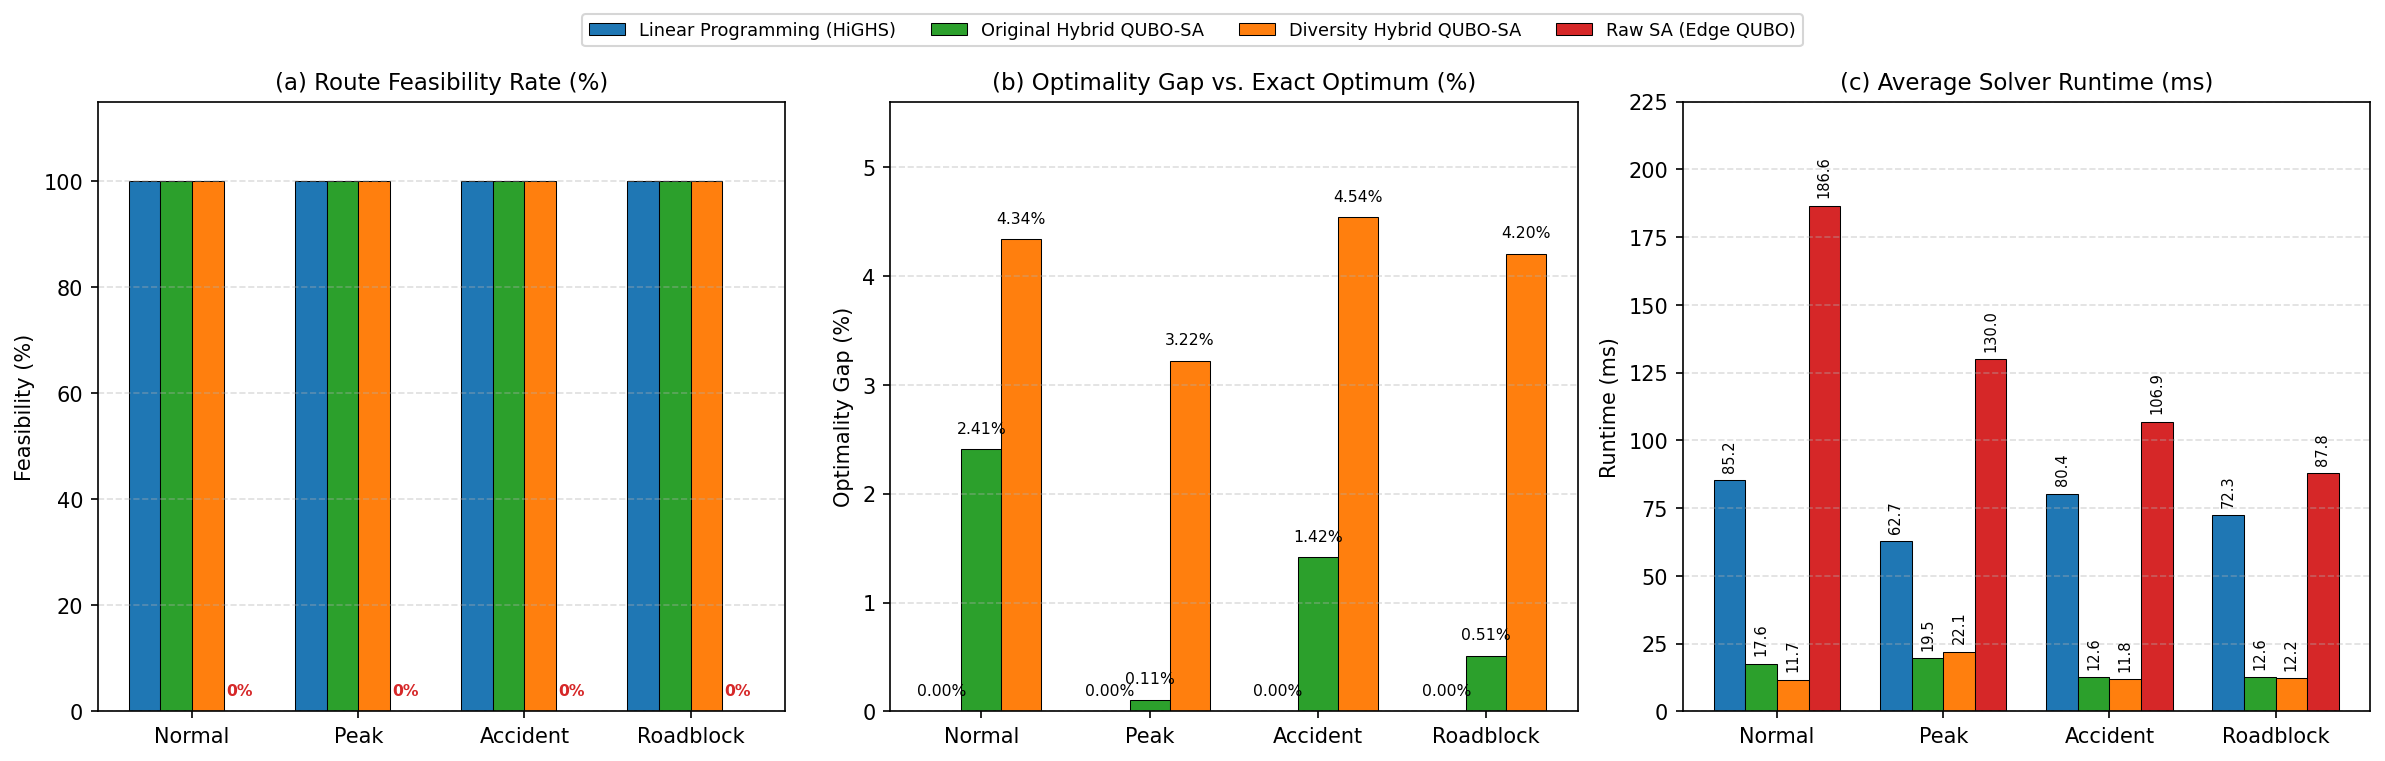

Saved high-resolution figure: phase1_lp_vs_qubo_benchmark.png


In [14]:
import matplotlib.pyplot as plt
import numpy as np

# Ensure consistent ordering of scenarios and methods
scenario_order = ["Normal", "Peak", "Accident", "Roadblock"]
method_order = [
    "Linear Programming (HiGHS)",
    "Original Hybrid QUBO-SA",
    "Diversity Hybrid QUBO-SA",
    "Raw SA (Edge QUBO)"
]
colors = ["#1f77b4", "#2ca02c", "#ff7f0e", "#d62728"]

plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "legend.fontsize": 8.5,
    "figure.dpi": 150
})

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
x = np.arange(len(scenario_order))
width = 0.19

# Panel A: Feasibility Rate (%)
ax = axes[0]
for idx, (method, color) in enumerate(zip(method_order, colors)):
    vals = [
        df_full_phase1[(df_full_phase1["Scenario"] == s) & (df_full_phase1["Method"] == method)]["Feasibility (%)"].values[0]
        for s in scenario_order
    ]
    bars = ax.bar(x + (idx - 1.5) * width, vals, width, label=method, color=color, edgecolor="black", linewidth=0.5)
    for bar, v in zip(bars, vals):
        if v == 0:
            ax.text(bar.get_x() + bar.get_width() / 2, 2.5, "0%", ha="center", va="bottom", fontsize=7.5, color="#d62728", fontweight="bold")

ax.set_title("(a) Route Feasibility Rate (%)")
ax.set_ylabel("Feasibility (%)")
ax.set_xticks(x)
ax.set_xticklabels(scenario_order)
ax.set_ylim(0, 115)
ax.grid(axis="y", linestyle="--", alpha=0.4)

# Panel B: Optimality Gap (%) — Feasible Solvers Only
ax = axes[1]
feasible_methods = method_order[:3]
for idx, (method, color) in enumerate(zip(feasible_methods, colors[:3])):
    vals = [
        df_full_phase1[(df_full_phase1["Scenario"] == s) & (df_full_phase1["Method"] == method)]["Optimality Gap (%)"].values[0]
        for s in scenario_order
    ]
    bars = ax.bar(x + (idx - 1.0) * (width * 1.25), vals, width * 1.25, label=method, color=color, edgecolor="black", linewidth=0.5)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, v + 0.12, f"{v:.2f}%", ha="center", va="bottom", fontsize=7.5)

ax.set_title("(b) Optimality Gap vs. Exact Optimum (%)")
ax.set_ylabel("Optimality Gap (%)")
ax.set_xticks(x)
ax.set_xticklabels(scenario_order)
ax.set_ylim(0, 5.6)
ax.grid(axis="y", linestyle="--", alpha=0.4)

# Panel C: Average Solver Runtime (ms)
ax = axes[2]
for idx, (method, color) in enumerate(zip(method_order, colors)):
    vals = [
        df_full_phase1[(df_full_phase1["Scenario"] == s) & (df_full_phase1["Method"] == method)]["Avg Runtime (ms)"].values[0]
        for s in scenario_order
    ]
    bars = ax.bar(x + (idx - 1.5) * width, vals, width, label=method, color=color, edgecolor="black", linewidth=0.5)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, v + 3.0, f"{v:.1f}", ha="center", va="bottom", fontsize=7.0, rotation=90)

ax.set_title("(c) Average Solver Runtime (ms)")
ax.set_ylabel("Runtime (ms)")
ax.set_xticks(x)
ax.set_xticklabels(scenario_order)
ax.set_ylim(0, 225)
ax.grid(axis="y", linestyle="--", alpha=0.4)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.06), frameon=True)
plt.tight_layout()
plt.savefig("phase1_lp_vs_qubo_benchmark.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved high-resolution figure: phase1_lp_vs_qubo_benchmark.png")